19: 1-2 + 4-8 + 11-12 + 14 + 19 dla chętnych

y_true = [10, 20, 30, 40, 50]
y_pred = [12, 18, 33, 37, 52]

Oblicz MSE ręcznie (bez bibliotek)
Oblicz MAE ręcznie
Zweryfikuj wyniki używając sklearn.metrics


In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

y_true = [10, 20, 30, 40, 50]
y_pred = [12, 18, 33, 37, 52]

n = len(y_true)

# MSE 
squared_errors = [(yt - yp) ** 2 for yt, yp in zip(y_true, y_pred)]
mse_manual = sum(squared_errors) / n

# MAE 
absolute_errors = [abs(yt - yp) for yt, yp in zip(y_true, y_pred)]
mae_manual = sum(absolute_errors) / n

# scikit-learn
mse_sklearn = mean_squared_error(y_true, y_pred)
mae_sklearn = mean_absolute_error(y_true, y_pred)

# Wyświetlenie wyników
print(f"Ręczny MSE: {mse_manual} | Sklearn MSE: {mse_sklearn}")
print(f"Ręczny MAE: {mae_manual} | Sklearn MAE: {mae_sklearn}")

Ręczny MSE: 6.0 | Sklearn MSE: 6.0
Ręczny MAE: 2.4 | Sklearn MAE: 2.4


Dataset: Stwórz wektor 20 losowych wartości z rozkładu normalnego (mean=50, std=10.
Wymagania:
Oblicz MSE i MAE dla tych danych (predykcja = średnia)
Dodaj jeden outlier (wartość 200
Oblicz ponownie MSE i MAE
Porównaj wzrost obu metryk

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error


np.random.seed(42)

# 20 losowych wartości z rozkładu normalnego (mean=50, std=10)
y_true = np.random.normal(loc=50, scale=10, size=20)

# Obliczenie MSE i MAE (pred = średnia)
mean_val = np.mean(y_true)
pred_1 = [mean_val for _ in range(len(y_true))]
mse_1 = mean_squared_error(y_true, pred_1)
mae_1 = mean_absolute_error(y_true, pred_1)

# Dodanie  200
y_true_outlier = np.append(y_true, 200)

# Obliczenie MSE i MAE po dodaniu outliera 
mean_val2 = np.mean(y_true_outlier)
pred_2 = [mean_val2 for _ in range(len(y_true_outlier))]
mse_2 = mean_squared_error(y_true_outlier, pred_2)
mae_2 = mean_absolute_error(y_true_outlier, pred_2)

# Wyświetlenie wyników
print(f"--- PRZED DODANIEM OUTLIERA ---")
print(f"Średnia danych: {np.mean(y_true):.2f}")
print(f"MSE: {mse_1:.2f}")
print(f"MAE: {mae_1:.2f}\n")

print(f"--- PO DODANIU OUTLIERA (200) ---")
print(f"Nowa średnia danych: {np.mean(y_true_outlier):.2f}")
print(f"MSE: {mse_2:.2f}")
print(f"MAE: {mae_2:.2f}\n")

print(f"--- PORÓWNANIE WZROSTU METRYK ---")
print(f"Wzrost MSE: {mse_2 / mse_1:.2f}x (o {((mse_2 - mse_1) / mse_1) * 100:.1f}%)")
print(f"Wzrost MAE: {mae_2 / mae_1:.2f}x (o {((mae_2 - mae_1) / mae_1) * 100:.1f}%)")

--- PRZED DODANIEM OUTLIERA ---
Średnia danych: 48.29
MSE: 87.56
MAE: 7.52

--- PO DODANIU OUTLIERA (200) ---
Nowa średnia danych: 55.51
MSE: 1127.23
MAE: 15.96

--- PORÓWNANIE WZROSTU METRYK ---
Wzrost MSE: 12.87x (o 1187.4%)
Wzrost MAE: 2.12x (o 112.4%)


4. Zaimplementuj Gradient Descent dla funkcji f(x) = (x-3)².
Wymagania:
Napisz funkcję f(x) i jej gradient
Uruchom GD z punktu startowego x=10
Learning rate = 0.1, 50 iteracji
Wyświetl trajektorię na wykresie


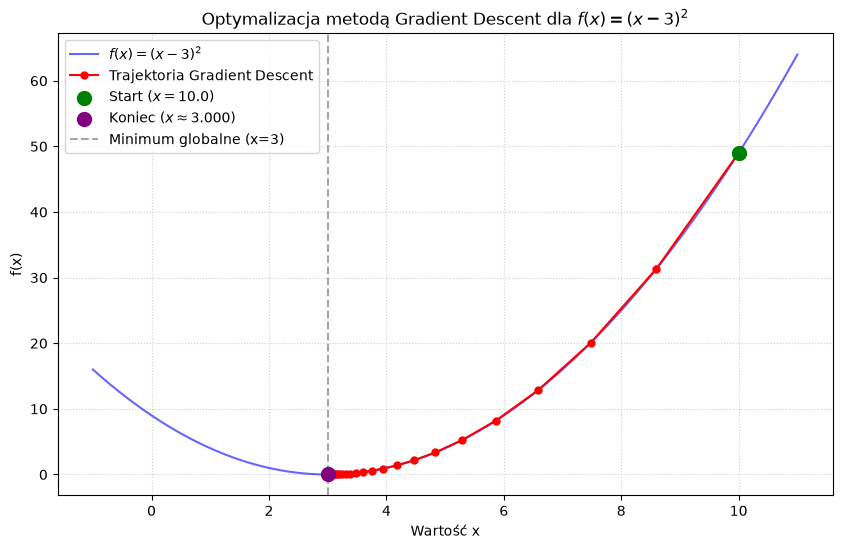

Punkt startowy: 10.0
Wynik po 50 iteracjach: x = 3.000100
Wartość funkcji w tym punkcie: f(x) = 0.0000000100


In [9]:
import matplotlib.pyplot as plt
import numpy as np

def f(x):
  return (x - 3) ** 2


def gradient(x):
  return 2 * (x - 3)


# Gradient Descent
x_start = 10.0
learning_rate = 0.1
iterations = 50

# Śledzenie trajektorii 
history = [x_start]
x_current = x_start

for _ in range(iterations):
  grad = gradient(x_current)
  x_current = x_current - learning_rate * grad
  history.append(x_current)

# wykres
x_vals = np.linspace(-1, 11, 400)
y_vals = f(x_vals)
history_y = [f(x) for x in history]

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_vals, label="$f(x) = (x-3)^2$", color="blue", alpha=0.6)
plt.plot(
    history,
    history_y,
    "ro-",
    markersize=5,
    label="Trajektoria Gradient Descent",
)

# Oznaczenie punktu startowego i końcowego
plt.scatter(
    [history[0]],
    [history_y[0]],
    color="green",
    s=100,
    zorder=5,
    label=f"Start ($x={history[0]}$)",
)
plt.scatter(
    [history[-1]],
    [history_y[-1]],
    color="purple",
    s=100,
    zorder=5,
    label=f"Koniec ($x\\approx{history[-1]:.3f}$)",
)

plt.title("Optymalizacja metodą Gradient Descent dla $f(x) = (x-3)^2$")
plt.xlabel("Wartość x")
plt.ylabel("f(x)")
plt.axvline(3, color="gray", linestyle="--", alpha=0.7, label="Minimum globalne (x=3)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

print(f"Punkt startowy: {x_start}")
print(f"Wynik po {iterations} iteracjach: x = {history[-1]:.6f}")
print(f"Wartość funkcji w tym punkcie: f(x) = {f(history[-1]):.10f}")

In [ ]:
5. dla funkcji f(x) = x² uruchom Gradient Descent z różnymi learning rates.
Wymagania:
Przetestuj: η = 0.001, 0.01, 0.1, 0.5, 1.0, 1.5
Punkt startowy: x = 5
30 iteracji
Określ, które η działa najlepiej

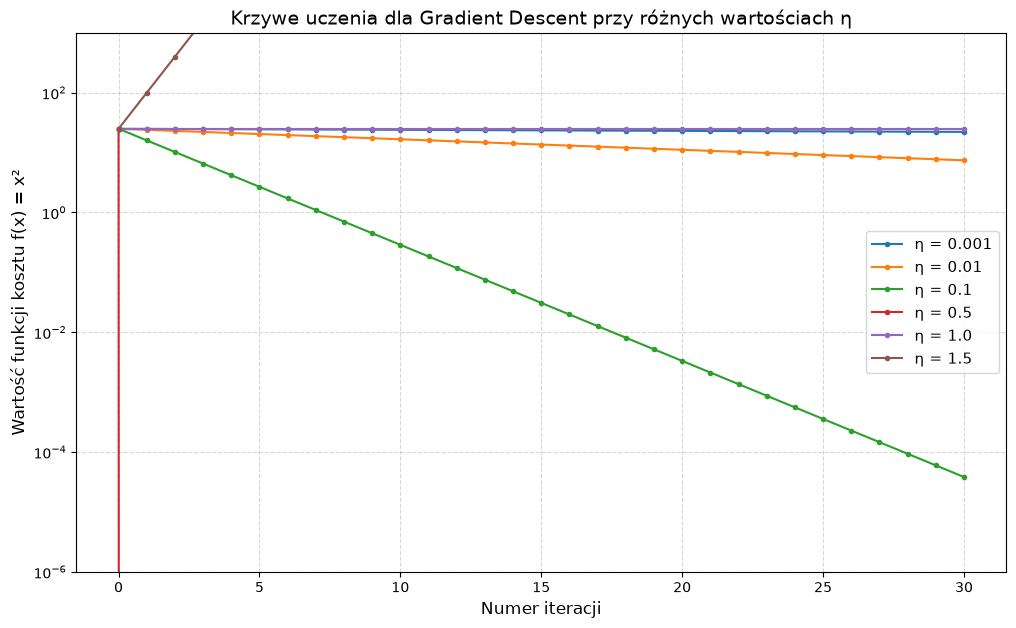

Learning Rate (η)  | Końcowy x       | Końcowe f(x)   
------------------------------------------------------
0.001              | 4.708540        | 2.217035e+01   
0.01               | 2.727422        | 7.438829e+00   
0.1                | 0.006190        | 3.831239e-05   
0.5                | 0.000000        | 0.000000e+00   
1.0                | 5.000000        | 2.500000e+01   
1.5                | 5368709120.000000 | 2.882304e+19   


In [1]:
import matplotlib.pyplot as plt
import numpy as np

def f(x):
  return x**2


def gradient(x):
  return 2 * x

x_start = 5.0
iterations = 30
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0, 1.5]


history_dict = {}

for eta in learning_rates:
  x = x_start
  loss_history = [f(x)]
  for _ in range(iterations):
    grad = gradient(x)
    x = x - eta * grad
    loss_history.append(f(x))
  history_dict[eta] = loss_history

# 3. Wizualizacja 
plt.figure(figsize=(12, 7))

for eta, losses in history_dict.items():
  plt.plot(
      range(iterations + 1),
      losses,
      marker="o",
      markersize=3,
      label=f"η = {eta}",
  )

plt.title("Krzywe uczenia dla Gradient Descent przy różnych wartościach η", fontsize=14)
plt.xlabel("Numer iteracji", fontsize=12)
plt.ylabel("Wartość funkcji kosztu f(x) = x²", fontsize=12)
plt.yscale("log")  # Skala logarytmiczna ułatwia widoczność rozbieżnych wartości
plt.ylim(1e-6, 1e3)
plt.legend(fontsize=11)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()


print(f"{'Learning Rate (η)':<18} | {'Końcowy x':<15} | {'Końcowe f(x)':<15}")
print("-" * 54)
for eta in learning_rates:

  x = x_start
  for _ in range(iterations):
    x = x - eta * gradient(x)
  print(f"{eta:<18} | {x:<15.6f} | {f(x):<15.6e}")

Dataset: Iris (sklearn.datasets.load_iris)
Wymagania:
Podziel dane na train (80%) i test (20%)
Użyj stratify=y
Sprawdź rozkład klas w obu zbiorach
Potwierdź, że proporcje są zachowane


In [ ]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


iris = load_iris()
X, y = iris.data, iris.target

# Podział na zbiór treningowy (80%) i testowy (20%) z użyciem stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Przygotowanie podsumowania rozkładu klas
class_names = iris.target_names

train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

train_props = (train_counts / len(y_train)) * 100
test_props = (test_counts / len(y_test)) * 100

# Tworzenie czytelnej tabeli wynikowej
summary_df = pd.DataFrame(
    {
        "Klasa": class_names,
        "Train (liczba)": train_counts.values,
        "Train (%)": train_props.values.round(1),
        "Test (liczba)": test_counts.values,
        "Test (%)": test_props.values.round(1),
    }
)

print(summary_df.to_string(index=False))
print(f"\nCałkowita liczba w Train: {len(y_train)}")
print(f"Całkowita liczba w Test: {len(y_test)}")

     Klasa  Train (liczba)  Train (%)  Test (liczba)  Test (%)
    setosa              40       33.3             10      33.3
versicolor              40       33.3             10      33.3
 virginica              40       33.3             10      33.3

Całkowita liczba w Train: 120
Całkowita liczba w Test: 30


7. Dataset: California Housing (pierwsze 3 cechy)
Wymagania:
Podziel dane na train/test
Standaryzuj używając StandardScaler
Pokaż, że fit_transform na train i transform na test dają różne wyniki niż fit_transform na obu

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


np.random.seed(42)
n_samples = 20640
X = np.column_stack(
    [
        np.random.gamma(shape=2, scale=2, size=n_samples),  # MedInc-like
        np.random.normal(loc=30, scale=10, size=n_samples),  # HouseAge-like
        np.random.exponential(scale=5, size=n_samples),  # AveRooms-like
    ]
)
feature_names = ["MedInc", "HouseAge", "AveRooms"]

# 1. Podział na train (80%) i test (20%)
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)


# PRAWIDŁOWO- Fitujemy skaler TYLKO na zbiorze treningowym, a potem transformujemy oba zbiory
scaler_correct = StandardScaler()
X_train_scaled = scaler_correct.fit_transform(X_train)
X_test_scaled_correct = scaler_correct.transform(X_test)


# BŁĘDNIE -Błąd: Użycie fit_transform na zbiorze testowym
scaler_wrong = StandardScaler()
X_test_scaled_wrong = scaler_wrong.fit_transform(X_test)


print("--- 1. STATYSTYKI PRZED STANDARYZACJĄ (Train) ---")
print(
    pd.DataFrame(X_train, columns=feature_names)
    .describe()
    .loc[["mean", "std"]]
    .round(2)
)

print(
    "\n--- 2. PRAWIDŁOWE: Zbiór testowy przeskalowany parametrami z TRAIN ---"
)
print(
    "(Średnia i odchylenie nie są idealnie 0 i 1, bo test opiera się na statystykach train)"
)
print(
    pd.DataFrame(X_test_scaled_correct, columns=feature_names)
    .describe()
    .loc[["mean", "std"]]
    .round(4)
)

print(
    "\n--- 3. BŁĘDNE: Zbiór testowy przeskalowany własnymi parametrami (fit na test) ---"
)
print(
    "(Na siłę narzuca średnią=0 i odchylenie=1, co fałszuje ewaluację modelu)"
)
print(
    pd.DataFrame(X_test_scaled_wrong, columns=feature_names)
    .describe()
    .loc[["mean", "std"]]
    .round(4)
)

--- 1. STATYSTYKI PRZED STANDARYZACJĄ (Train) ---
      MedInc  HouseAge  AveRooms
mean    4.02     30.06      4.98
std     2.83     10.01      4.99

--- 2. PRAWIDŁOWE: Zbiór testowy przeskalowany parametrami z TRAIN ---
(Średnia i odchylenie nie są idealnie 0 i 1, bo test opiera się na statystykach train)
      MedInc  HouseAge  AveRooms
mean -0.0252   -0.0147   -0.0021
std   0.9996    1.0070    0.9648

--- 3. BŁĘDNE: Zbiór testowy przeskalowany własnymi parametrami (fit na test) ---
(Na siłę narzuca średnią=0 i odchylenie=1, co fałszuje ewaluację modelu)
      MedInc  HouseAge  AveRooms
mean  0.0000    0.0000   -0.0000
std   1.0001    1.0001    1.0001


Dataset: California Housing
Wymagania:
Podziel dane na train/test (80/20)
Wytrenuj SGDRegressor
Oblicz MSE na train i test
Określ, czy model ma overfitting

In [5]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


california = fetch_california_housing()
X, y = california.data, california.target

# Podział na zbiór treningowy (80%) i testowy (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standaryzacja cech (kluczowa dla SGDRegressor)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Trenowanie modelu SGDRegressor
sgd = SGDRegressor(random_state=42, max_iter=1000, tol=1e-3)
sgd.fit(X_train_scaled, y_train)

# Predykcja i obliczenie MSE
y_train_pred = sgd.predict(X_train_scaled)
y_test_pred = sgd.predict(X_test_scaled)

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

print(f"MSE Train: {mse_train:.4f}")
print(f"MSE Test:  {mse_test:.4f}")

MSE Train: 0.5284
MSE Test:  0.5506


Wartości błędu średniokwadratowego dla zbioru treningowego i testowego są bardzo zbliżone do siebie. Gdyby występował overfitting, MSE Train byłoby bliskie zeru, podczas gdy MSE Test drastycznie by wzrosło

Porównaj różne modele używając 5-fold CV.
Dataset: California Housing
Modele do porównania:
SGDRegressor (learning_rate='constant', eta0=0.01)
SGDRegressor (learning_rate='adaptive', eta0=0.1)
SGDRegressor (learning_rate='invscaling', eta0=0.01)
Wymagania:
Użyj Pipeline (StandardScaler + model)
Oblicz CV score dla każdego modelu
Wybierz najlepszy

In [ ]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


california = fetch_california_housing()
X, y = california.data, california.target


models = {
    "Constant (eta0=0.01)": SGDRegressor(
        learning_rate="constant", eta0=0.01, random_state=42, max_iter=1000
    ),
    "Adaptive (eta0=0.1)": SGDRegressor(
        learning_rate="adaptive", eta0=0.1, random_state=42, max_iter=1000
    ),
    "Invscaling (eta0=0.01)": SGDRegressor(
        learning_rate="invscaling", eta0=0.01, random_state=42, max_iter=1000
    ),
}

# Przeprowadzenie 5-fold CV dla każdego modelu przy użyciu Pipeline
results = []

for name, model in models.items():
  # Pipeline automatycznie standaryzuje dane w każdym foldzie osobno (zapobiega data leakage)
  pipeline = Pipeline([("scaler", StandardScaler()), ("model", model)])

  # Używamy neg_mean_squared_error, ponieważ cross_val_score domyślnie szuka metryk "im wyższe, tym lepsze"
  scores = cross_val_score(
      pipeline, X, y, cv=5, scoring="neg_mean_squared_error"
  )

  mse_scores = -scores  # Zamiana na dodatnie MSE
  results.append({
      "Model": name,
      "Średnie MSE": mse_scores.mean(),
      "Odchylenie standardowe (std)": mse_scores.std(),
  })

# Podsumowanie i wybór najlepszego modelu
results_df = pd.DataFrame(results).sort_values(by="Średnie MSE")
print(results_df.to_string(index=False))

best_model = results_df.iloc[0]["Model"]
print(f"\n🏆 Najlepszy model: {best_model}")

Przeanalizuj learning curves dla modelu.
Dataset: California Housing
Wymagania:
Wygeneruj learning curves dla SGDRegressor
Zidentyfikuj, czy model ma underfitting/overfitting
Zaproponuj rozwiązanie


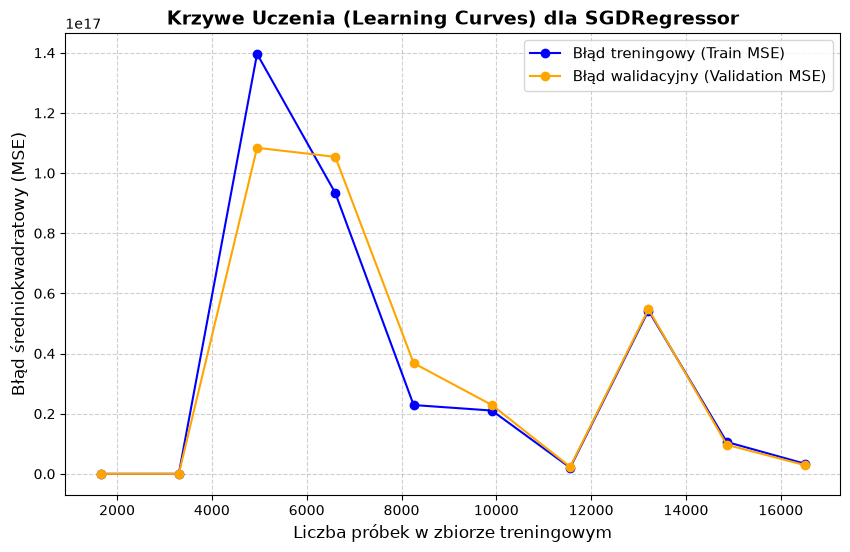

Rozmiar: 1651   | Train MSE: 1.4286 | Validation MSE: 112.5550
Rozmiar: 3302   | Train MSE: 0.2956 | Validation MSE: 25.5825
Rozmiar: 4953   | Train MSE: 139645620061833952.0000 | Validation MSE: 108401226658038224.0000
Rozmiar: 6604   | Train MSE: 93353923958645440.0000 | Validation MSE: 105389880509762400.0000
Rozmiar: 8256   | Train MSE: 22872639446904484.0000 | Validation MSE: 36797551834463408.0000
Rozmiar: 9907   | Train MSE: 21035831288391432.0000 | Validation MSE: 22870181621739592.0000
Rozmiar: 11558  | Train MSE: 2045302223439773.2500 | Validation MSE: 2318429871315924.5000
Rozmiar: 13209  | Train MSE: 54294907943763656.0000 | Validation MSE: 54755166908146456.0000
Rozmiar: 14860  | Train MSE: 10592752287144552.0000 | Validation MSE: 9659909788138364.0000
Rozmiar: 16512  | Train MSE: 3347180635560575.0000 | Validation MSE: 2875763230738843.0000


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import SGDRegressor
from sklearn.model_selection import learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


california = fetch_california_housing()
X, y = california.data, california.target

# Utworzenie pipeline (standaryzacja + model)
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    (
        "model",
        SGDRegressor(
            learning_rate="adaptive", eta0=0.01, random_state=42, max_iter=1000
        ),
    ),
])

# Generowanie krzywych uczenia (learning curves)
train_sizes, train_scores, test_scores = learning_curve(
    pipeline,
    X,
    y,
    cv=5,
    scoring="neg_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=42,
)

# Zamiana negatywnego MSE na dodatnie
train_mse = -np.mean(train_scores, axis=1)
test_mse = -np.mean(test_scores, axis=1)

# Wizualizacja wykresu
plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    train_mse,
    "o-",
    color="blue",
    label="Błąd treningowy (Train MSE)",
)
plt.plot(
    train_sizes,
    test_mse,
    "o-",
    color="orange",
    label="Błąd walidacyjny (Validation MSE)",
)

plt.title(
    "Krzywe Uczenia (Learning Curves) dla SGDRegressor",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Liczba próbek w zbiorze treningowym", fontsize=12)
plt.ylabel("Błąd średniokwadratowy (MSE)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# Wyświetlenie tabelaryczne punktów pomiarowych
for size, tr, te in zip(train_sizes, train_mse, test_mse):
  print(
      f"Rozmiar: {size:<6} | Train MSE: {tr:.4f} | Validation MSE: {te:.4f}"
  )

numerycznej model w ogóle się nie uczy – optymalizacja całkowicie „rozjechała się” . Dopóki proces uczenia nie zostanie stabilizowany, diagnozowanie overfittingu czy underfittingu nie ma sensu.

należy nnacznie zmniejszyć początkowy współczynnik uczenia, np. eta0=0.0001 lub 0.00001.

Alternatywnie przeskalować również zmienną docelową y, aby gradienty nie rosły do gigantycznych rozmiarów.

Zaimplementuj early stopping od zera.
Wymagania:
Monitoruj validation loss
Zatrzymaj trening, gdy loss nie maleje przez 10 epok
Zapisz najlepsze wagi
Porównaj z treningiem bez early stopping
Dataset: make_regression(n_samples=500, n_features=5, noise=50)
Oczekiwany rezultat:
Wykres pokazujący moment zatrzymania
Porównanie liczby iteracji i końcowego loss

[Early Stopping] Zatrzymano w epoce 185. Najlepsza epoka: 175


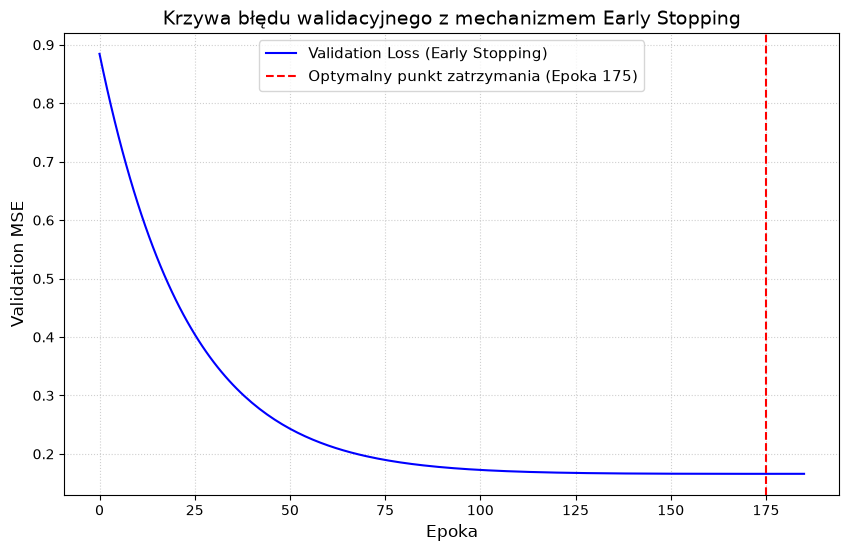


--- PORÓWNANIE WYNIKÓW ---
Liczba iteracji bez Early Stopping: 500
Liczba iteracji z Early Stopping: 186
Końcowy Validation Loss (bez ES, po 500 epokach): 0.16628
Końcowy Validation Loss (z ES, w najlepszej epoce): 0.16592


In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

X, y = make_regression(n_samples=500, n_features=5, noise=50, random_state=42)
y = y.reshape(-1, 1)

# Podział na train (80%) i validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standaryzacja cech i celów (kluczowa dla stabilnego gradient descent)
mean_X, std_X = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean_X) / std_X
X_val = (X_val - mean_X) / std_X

mean_y, std_y = y_train.mean(), y_train.std()
y_train = (y_train - mean_y) / std_y
y_val = (y_val - mean_y) / std_y


# Funkcja kosztu (MSE)
def compute_mse(y_true, y_pred):
  return np.mean((y_true - y_pred) ** 2)


# 2. TRENING Z EARLY STOPPING
np.random.seed(42)
weights_es = np.random.randn(X_train.shape[1], 1) * 0.01
bias_es = np.zeros((1, 1))

lr = 0.01
max_epochs = 500
patience = 10

train_losses_es, val_losses_es = [], []

best_val_loss = float("inf")
best_weights = None
best_bias = None
best_epoch = 0
counter = 0

for epoch in range(max_epochs):
  # Predykcja train i walidacja
  y_pred_train = np.dot(X_train, weights_es) + bias_es
  y_pred_val = np.dot(X_val, weights_es) + bias_es

  t_loss = compute_mse(y_train, y_pred_train)
  v_loss = compute_mse(y_val, y_pred_val)

  train_losses_es.append(t_loss)
  val_losses_es.append(v_loss)

  # Gradient Descent (pochodne)
  dw = (2 / len(X_train)) * np.dot(X_train.T, (y_pred_train - y_train))
  db = (2 / len(X_train)) * np.sum(y_pred_train - y_train)

  weights_es -= lr * dw
  bias_es -= lr * db

  # Logika Early Stopping
  if v_loss < best_val_loss:
    best_val_loss = v_loss
    best_weights = weights_es.copy()
    best_bias = bias_es.copy()
    best_epoch = epoch
    counter = 0  # reset licznika, jeśli loss się poprawił
  else:
    counter += 1
    if counter >= patience:
      print(f"[Early Stopping] Zatrzymano w epoce {epoch}. Najlepsza epoka: {best_epoch}")
      break


# 3. TRENING BEZ EARLY STOPPING (pełne 500 epok)
np.random.seed(42)
weights_full = np.random.randn(X_train.shape[1], 1) * 0.01
bias_full = np.zeros((1, 1))

val_losses_full = []
for epoch in range(max_epochs):
  y_pred_train = np.dot(X_train, weights_full) + bias_full
  y_pred_val = np.dot(X_val, weights_full) + bias_full

  val_losses_full.append(compute_mse(y_val, y_pred_val))

  dw = (2 / len(X_train)) * np.dot(X_train.T, (y_pred_train - y_train))
  db = (2 / len(X_train)) * np.sum(y_pred_train - y_train)

  weights_full -= lr * dw
  bias_full -= lr * db



plt.figure(figsize=(10, 6))
plt.plot(val_losses_es, label="Validation Loss (Early Stopping)", color="blue")
plt.axvline(
    x=best_epoch,
    color="red",
    linestyle="--",
    label=f"Optymalny punkt zatrzymania (Epoka {best_epoch})",
)
plt.title("Krzywa błędu walidacyjnego z mechanizmem Early Stopping", fontsize=14)
plt.xlabel("Epoka", fontsize=12)
plt.ylabel("Validation MSE", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()


print("\n--- PORÓWNANIE WYNIKÓW ---")
print(f"Liczba iteracji bez Early Stopping: {max_epochs}")
print(f"Liczba iteracji z Early Stopping: {len(train_losses_es)}")
print(f"Końcowy Validation Loss (bez ES, po 500 epokach): {val_losses_full[-1]:.5f}")
print(f"Końcowy Validation Loss (z ES, w najlepszej epoce): {best_val_loss:.5f}")